Lander Dirix

## Overzicht
* 1. Data en imports
* 2. EDA
    * 2.1 Overzicht van de dataset
    * 2.2 Nummers per artiest en album
    * 2.3 Kolomtypes
    * 2.4 Opschonen van kolommen
        * Onnuttige kolommen
        * Redundante kolommen (duration)
        * Tekstkolommen
        * Verschillende formats (3 precizies van datum, veel placeholder datums, compilaties krijgen de datum van de heruitgave)
    * Sortering en groepering 
        * gesorteerd op releasedatum
        * nummers van hetzelfde album en dezelfde artiest staan bij elkaar
    * Kwaliteit van de data
        * Duplicaten
        * Ontbrekende waarden
        * Outliers
    * splitsen van sets
    *  Doelveld (genre)
        * Aantal genres en verdeling
        * Artiesten per genre
        * Genres per artiest
        * Genres per album
* 3. Splitsen
* 4. Verdiepende EDA
    * Histogrammen per audio feature
    * Outliers
    * Correlatiematrix
    * Boxplots
* 5. Preprocessing en feature engineering
* 6. Modellen en tuning
* 7. Evaluatie
* 8. Conclusie

# 1. Data en imports

## Import statements

In [2]:
import pandas as pd
import seaborn as sn
import numpy as np
import matplotlib.pyplot as plt
import os


original_df = pd.read_csv("./Spotify_tracks_final.csv")

RANDOM_STATE = 1

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)
pd.set_option("display.float_format", "{:.3f}".format)

# 2. EDA

## 2.1 Overzicht van de dataset

In [8]:
n_rows, n_cols = original_df.shape
print(f"Rijen: {n_rows:,}")
print(f"Kolommen: {n_cols}")
print(f"Bestandsgrootte: {os.path.getsize('./Spotify_tracks_final.csv') / 1e9:.2f} GB")
print(f"Geheugengebruik: {original_df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Rijen: 2,112,746
Kolommen: 30
Bestandsgrootte: 0.82 GB
Geheugengebruik: 2.01 GB


In [31]:
original_df.head(10)

,Unnamed: 0,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
0,0,"Divenire: No. 9, Fly - Intouchables",5u5scm02d5wN6nWFKuqEUK,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,2,265653,False,https://p.scdn.co/mp3-preview/81f71c...,ambient,0.990,0.184,0.033,0.877,1,0.100,-28.184,0,0.037,168.133,3,0.035,0,265.653,4.428
1,1,Spiegel im Spiegel - Heaven,1wV4SNFEXWawsyjBCGwkiw,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,349120,False,https://p.scdn.co/mp3-preview/040ea9...,ambient,0.985,0.250,0.015,0.971,5,0.067,-30.646,1,0.037,136.864,5,0.039,0,349.120,5.819
2,2,Truman Sleeps - The Trumanshow,4gYub3T80gNfU9F4Df98AR,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,1,128039,False,https://p.scdn.co/mp3-preview/e9a7cd...,ambient,0.993,0.269,0.021,0.883,5,0.139,-24.620,0,0.040,69.487,4,0.041,0,128.039,2.134
3,3,The Heart Askes Pleasure First - The...,6sXRgSAQsySTM7kH1pM07Y,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,190960,False,https://p.scdn.co/mp3-preview/9a33da...,ambient,0.995,0.230,0.138,0.885,4,0.101,-19.591,0,0.037,165.197,3,0.171,0,190.960,3.183
4,4,3 Gymnopédies: I. Lent et douloureux,7Eytd0e0mNFiSWIE132H76,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,4,338933,False,https://p.scdn.co/mp3-preview/d31979...,ambient,0.995,0.611,0.002,0.967,7,0.082,-37.782,1,0.286,134.237,3,0.508,0,338.933,5.649
5,5,Comptine d'un autre été - Le fabuleu...,36xrCDskORciDQupSJdoQ0,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,141133,False,https://p.scdn.co/mp3-preview/926917...,ambient,0.968,0.391,0.111,0.933,7,0.099,-21.655,1,0.042,103.047,4,0.079,0,141.133,2.352
6,6,Someone To Watch Over Me,5RcvlmVx2xtFcp2Ta5pw7X,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,54,196666,False,NaN,blues,0.990,0.354,0.085,0.000,7,0.123,-13.738,1,0.035,97.684,1,0.197,1,196.666,3.278
7,7,I've Got A Crush On You,5DIVWgTeJ2fPIxaY9e7ZKn,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,53,196440,False,NaN,blues,0.986,0.455,0.106,0.000,2,0.122,-14.086,1,0.042,66.807,4,0.258,1,196.440,3.274
8,8,But Not For Me,65Dm4aRthohlvuuyKVydIu,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,23,195133,False,NaN,blues,0.986,0.410,0.098,0.000,4,0.174,-14.359,0,0.032,136.431,3,0.240,1,195.133,3.252
9,9,How Long Has This Been Going On?,0HEU3berJ5OBojU8XmEk1c,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,23,197666,False,NaN,blues,0.974,0.303,0.175,0.000,1,0.105,-14.203,0,0.038,168.743,4,0.250,1,197.666,3.294


In [34]:
cols = ["track_id", "album_id", "artist_id", "genre"]
display(original_df[cols].nunique().to_frame("aantal"))

,aantal
track_id,2112746
album_id,464281
artist_id,77854
genre,113


**Conclusie**

De dataset bevat 30 kolommen en meer dan 2,1 miljoen nummers, verdeeld over meer dan 464 duizend albums, bijna 78 duizend artiesten en 113 genres.

Het bestand is 0,82GB groot en neemt 2GB RAM in beslag. Daarom maken we zo weinig mogelijk kopieën en laten we ongebruikte kolommen vroeg vallen.


* **Multiklasse-probleem met vele klassen:** 
Met 113 genres haalt een model dat willekeurig gokt 1/113 = 0,9% accuracy. De echte baseline bepalen we na de analyse van de genreverdeling.
Omdat genres inhoudelijk vaak overlappen, is verwarring te verwachten. Daarom beslissen we later of we alle genres houden, de minst voorkomende genres laten vallen of verwante genres samenvoegen.


* **Groepering in de data:**
De eerste rijen zijn nummers van dezelfde artiest en hetzelfde album met hetzelfde genre. Een willekeurige split zou dus leakage kunnen veroorzaken. Dit onderzoeken we verder bij de verdeling per artiest en album en bepaalt hoe we de data splitsen.


## 2.2 Nummers per artiest en album

In [3]:
per_artiest = original_df.groupby("artist_id").size()
per_album = original_df.groupby("album_id").size()

overzicht = pd.DataFrame({
    "nummers per artiest": per_artiest.describe(percentiles=[.5, .9, .99]),
    "nummers per album": per_album.describe(percentiles=[.5, .9, .99]),
})
display(overzicht.round(1))

,nummers per artiest,nummers per album
count,77854.000,464281.000
mean,27.100,4.600
std,93.800,5.500
min,1.000,1.000
50%,8.000,2.000
90%,67.000,11.000
99%,256.000,22.000
max,10035.000,315.000


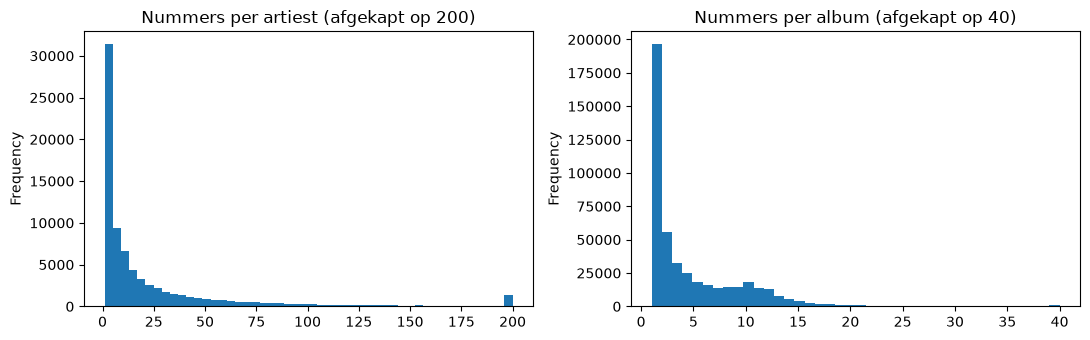

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
per_artiest.clip(upper=200).plot.hist(bins=50, ax=axes[0], title="Nummers per artiest (afgekapt op 200)")
per_album.clip(upper=40).plot.hist(bins=40, ax=axes[1], title="Nummers per album (afgekapt op 40)")
plt.tight_layout(); plt.show()

In [10]:
top_10 = per_artiest.sort_values(ascending=False).head(10)
display(original_df.drop_duplicates("artist_id").set_index("artist_id")
        .loc[top_10.index, ["artist_name"]].assign(n_nummers=top_10))

,artist_name,n_nummers
artist_id,,
5aIqB5nVVvmFsvSdExz408,Johann Sebastian Bach,10035
1U5zgr455OGyIkLNXvDdrf,Traditional,8737
4NJhFmfw43RLBLjQvxDuRS,Wolfgang Amadeus Mozart,6316
1JOQXgYdQV2yfrhewqx96o,Giuseppe Verdi,6104
5as8A4G47Ohu9NSWs3Je8U,Asha Bhosle,5492
61JrslREXq98hurYL2hYoc,Lata Mangeshkar,4214
1C1x4MVkql8AiABuTw6DgE,Richard Wagner,3935
2wOqMjp9TyABvtHdOSOTUS,Ludwig van Beethoven,3558
0roWUeP7Ac4yK4VN6L2gF4,Gioachino Rossini,3487


In [ ]:
top1_procent = per_artiest.nlargest(int(len(per_artiest) * 0.01)).sum() / n_rows
print(f"Top 1% van de artiesten bevat {top1_procent:.1%} van alle nummers")
print(f"Grootste artiest: {per_artiest.max() / n_rows:.2%} van alle nummers")

Top 1% van de artiesten bevat 19.4% van alle nummers
Grootste artiest: 0.47% van alle nummers


**Conclusie**

Beide verdelingen zijn sterk rechtsscheef.
De mediaan is 8 nummers per artiest en 2 per album, terwijl het gemiddelde veel hoger ligt (27,1 en 4,6). 
De top 1% van artiesten levert bijna 20% van alle nummers.

De grootste artiesten zijn vooral klassieke componisten (zoals Bach met meer dan 10 duizend nummers).
Dit is waarschijnlijk omdat de artiest vaak de componist is, in plaats van de uitvoerder.
"Traditional" is geen echte artiest maar een verzamelnaam voor onbekende uitvoerders.

* **Groepssplit:** 
Nummers van dezelfde artiest blijven samen in een split. De grootste artiest is ongeveer 0,5% van de data, dus er zouden geen folds mogen zijn die door één artiest is gedomineerd.

* **Verzamelnamen:** 
"Traditional" zal volledig in één split terecht komen. Dat is geen leakage, maar die nummers zijn onderling niet representatief voor één artiest.

* **Nog te controleren:** 
Bestaan zeldzame genres grotendeels uit één artiest, want dan wordt stratificatie moeilijk. Dat bekijken we bij de genreverdeling.

## 2.3 Kolomtypes

In [53]:
print(original_df.dtypes.value_counts())
original_df.dtypes.to_frame("aantal kolommen")

str        11
float64    11
int64       7
bool        1
Name: count, dtype: int64


,aantal kolommen
Unnamed: 0,int64
track_name,str
track_id,str
album_name,str
album_id,str
album_image,str
album_release_date,str
album_release_date_precision,str
artist_name,str
artist_id,str


In [14]:
# Onmogelijke waarden
print("tempo == 0:", (original_df["tempo"] == 0).sum())
print("time_signature == 0:", (original_df["time_signature"] == 0).sum())
print("duur < 10 s:", (original_df["duration_seconds"] < 10).sum())

tempo == 0: 2
time_signature == 0: 64
duur < 10 s: 1


In [16]:
# Nummers met dezelfde titel en artiest
dup = original_df.duplicated(subset=["artist_name", "track_name"], keep=False)
print(f"Nummers met zelfde titel en artiest: {dup.sum():,} ({dup.mean():.1%})")

Nummers met zelfde titel en artiest: 0 (0.0%)


De dataset bevat 11 tekstkolommen, 11 float-kolommen, 7 int-kolommen en 1 booleaanse kolom. 

Het type zegt niet altijd wat een kolom betekent: kolommen als key, mode en time_signature staan als integer, maar zijn categorisch.

## 2.5 Opschonen van kolommen

In [56]:
# Unnamed: 0 = achtergebleven csv-index?
print("Unnamed: 0 == rij-index:", (original_df["Unnamed: 0"] == original_df.index).all())

# Duur: drie eenheden voor dezelfde grootheid?
print("seconden == ms / 1000:", np.allclose(original_df["duration_seconds"], original_df["duration_ms"] / 1000))
print("minuten == ms / 60000:", np.allclose(original_df["duration_minutes"], original_df["duration_ms"] / 60000))

# database_shard_id: hangt hij samen met jaar of genre?
jaar = original_df["album_release_date"].str[:4].astype(int)
display(original_df.assign(jaar=jaar).groupby("database_shard_id")
        .agg(n=("track_id", "size"), jaar_mediaan=("jaar", "median"),
             n_genres=("genre", "nunique"),
             top_genres=("genre", lambda s: ", ".join(s.value_counts().head(3).index))))

# artist_id versus artist_name
namen_per_id = original_df.groupby("artist_id")["artist_name"].nunique()
ids_per_naam = original_df.groupby("artist_name")["artist_id"].nunique()
print("artist_id's met >1 naam:", (namen_per_id > 1).sum())
print("artist_name's met >1 id:", (ids_per_naam > 1).sum())

Unnamed: 0 == rij-index: False
seconden == ms / 1000: True
minuten == ms / 60000: True


,n,jaar_mediaan,n_genres,top_genres
database_shard_id,,,,
0,30245,2004.000,110,"ambient, indian, classical"
1,44343,1986.000,108,"blues, indian, french"
2,37431,1996.000,109,"british, folk, acoustic"
3,25312,2005.000,110,"children, german, indian"
4,46704,1984.000,106,"classical, blues, french"
...,...,...,...,...
108,9890,2012.000,112,"progressive-house, classical, disco"
109,10115,2014.000,111,"hardstyle, classical, german"
110,5706,2010.000,110,"dubstep, german, indian"


artist_id's met >1 naam: 0
artist_name's met >1 id: 420


Welke kolommen laten we vallen en welke houden we?

| Kolom | Beslissing | Reden |
|---|---|---|
| `Unnamed: 0` | Droppen | Achtergebleven index van het CSV-bestand |
| `track_id`, `album_id`, `artist_id` | Droppen | Identifiers zonder muzikale informatie |
| `album_image`, `preview_url` | Droppen | Urls |
| `database_shard_id` | Droppen | Technische id van het crawlen. TODO: onderbouwen met de tabel (geen samenhang met jaar of genre?) |
| `duration_ms`, `duration_minutes` | Droppen | Redundant: dezelfde informatie als `duration_seconds` |
| `track_name`, `album_name` | Droppen | Vrije tekst, niet bruikbaar zonder tekstverwerking |
| `album_release_date`, `album_release_date_precision` | Droppen na extractie | Gemengde formaten, alleen het jaar is bruikbaar (zie 2.4). We maken er `release_year` van |
| `artist_name` | Houden, enkel om te groeperen | Wordt geen feature, wel nodig voor de groepssplit (zie hieronder) |
| `genre` | Houden | Doelveld |
| `duration_seconds`, `release_year` | Houden | Eén duurkolom, en het uitgelezen jaar |
| `popularity`, `explicit` | Voorlopig houden | Metadata, geen eigenschap van het geluid. Beslissing over gebruik volgt bij de featureselectie |
| 12 audiofeatures | Houden | `acousticness`, `danceability`, `energy`, `instrumentalness`, `liveness`, `loudness`, `speechiness`, `tempo`, `valence`, `key`, `mode`, `time_signature` |

**`artist_id` versus `artist_name`.** Elke `artist_id` hoort bij precies één naam, maar 420 namen komen voor onder meer dan één id (77.854 id's tegenover 77.410 namen, dus 0,5%). TODO: conclusie (naamgenoten of dubbele profielen?). Daarom groeperen we bij het splitsen op `artist_name` in plaats van `artist_id`.

In [57]:
keep = ["artist_name", "genre", "duration_seconds", "popularity", "explicit",
        "acousticness", "danceability", "energy", "instrumentalness", "liveness",
        "loudness", "speechiness", "tempo", "valence", "key", "mode", "time_signature"]

df = original_df[keep].copy()
df["release_year"] = original_df["album_release_date"].str[:4].astype(int)

print(df.shape)
print(f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

(2112746, 18)
0.51 GB


# ----------------------------------------
## Overschotjes:

* ```Unnamed: 0``` is de index van de CSV file.
* ```track_id, album_id, artist_id``` zijn IDs.
* ```album_image, preview_url``` zijn URLs.
* ```database_shard_id``` is een ID dat aangeeft op welke specifieke databaseserver het record opgeslagen is.
* ```album_release_date``` heeft meerdere formaten, het kan een jaartal, jaar + maand of volledige datum zijn. ```album_release_date_precision``` toont aan welke het is.
* ```duration_ms, duration_seconds, duration_minutes``` bevatten dezelfde data in verschillende eenheden.
* De data is gesorteerd op releasedatum
* Het genre lijkt per artiest te zijn, niet per nummer (dit blijkt niet te zijn uit verdere tests)

In [18]:
original_df["genre"].value_counts()

genres_per_artist = original_df.groupby("artist_id")["genre"].nunique()
print("Artiesten:", genres_per_artist.size)

n_multi = (genres_per_artist > 1).sum()
print("Artiesten met >1 genre:", n_multi, f"({n_multi / genres_per_artist.size:.1%})")
print("Mediaan tracks per artiest:", original_df.groupby("artist_id").size().median())



Artiesten: 77854
Artiesten met >1 genre: 15613 (20.1%)
Mediaan tracks per artiest: 8.0


* 80% van de artiesten hebben maar 1 genre, dit betekent dat 

In [19]:
dup_track = original_df["track_id"].duplicated(keep=False)
print("Rijen waarvan track_id meer dan 1x voorkomt:", dup_track.sum(),
      f"({dup_track.mean():.1%})")

Rijen waarvan track_id meer dan 1x voorkomt: 0 (0.0%)


Track_id komt nooit meerdere keren voor

In [20]:
genres_per_album = original_df.groupby("album_id")["genre"].nunique()
print("Albums:", genres_per_album.size)
print("Albums met >1 genre:", (genres_per_album > 1).sum(),
      f"({(genres_per_album > 1).mean():.1%})")

Albums: 464281
Albums met >1 genre: 54796 (11.8%)


In [45]:
namen_per_id = original_df.groupby("artist_id")["artist_name"].nunique()
ids_per_naam = original_df.groupby("artist_name")["artist_id"].nunique()

print("artist_id's met >1 naam:", (namen_per_id > 1).sum())
print("artist_name's met >1 id:", (ids_per_naam > 1).sum())
print("Unieke ids:", original_df["artist_id"].nunique(), "| unieke namen:", original_df["artist_name"].nunique())


artist_id's met >1 naam: 0
artist_name's met >1 id: 420
Unieke ids: 77854 | unieke namen: 77410


In [44]:
namen = ids_per_naam[ids_per_naam > 1].index
sub = original_df[original_df["artist_name"].isin(namen)]

# per (naam, id): de top-3 genres als tekst
genres = (sub.groupby(["artist_name", "artist_id"])["genre"]
             .agg(lambda s: ", ".join(s.value_counts().head(3).index)))

# per naam: de genres van twee id's naast elkaar
paren = genres.groupby("artist_name").apply(lambda s: list(s)[:2])
tabel = pd.DataFrame(paren.tolist(), index=paren.index, columns=["genres_id1", "genres_id2"])

pd.set_option("display.max_colwidth", 60)
tabel.sample(25, random_state=42)

,genres_id1,genres_id2
artist_name,,
Germ,emo,black-metal
Shining,metal,black-metal
John Wayne,brazil,dancehall
The Controllers,punk,soul
Zola,k-pop,french
Camarão,forro,forro
Felix Martin,jazz,show-tunes
Franco,malay,gospel
Anomalie,jazz,black-metal
